<a href="https://colab.research.google.com/github/Aigulya0/ml-practice/blob/main/PR09_SVM_Aigul.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files

uploaded = files.upload()

Saving pr09-svm-template(1).zip to pr09-svm-template(1).zip


In [2]:
import zipfile
import os

zip_name = "pr09-svm-template(1).zip"

with zipfile.ZipFile(zip_name, 'r') as zip_ref:
    zip_ref.extractall("/content/")

os.chdir("/content/pr09-svm")

print("Файлы проекта:")
print(os.listdir())


Файлы проекта:
['run_all.py', 'svm_rbf_C1.png', 'svm_linear.png', 'svm_rbf.png', 'nb.py', 'svm_rbf_C0.01.png', 'svm_rbf_C100.png', 'grid.png', 'nb_c.py', 'README.txt', 'o_churn_synthetic.csv', 'transcript.txt', 'nb_b.py']


In [3]:
!pip install -q numpy pandas matplotlib scikit-learn xgboost


In [4]:
import sklearn
import numpy
import pandas
import matplotlib

print("Scikit-learn:", sklearn.__version__)
print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("Matplotlib:", matplotlib.__version__)



Scikit-learn: 1.6.1
NumPy: 2.4.6
Pandas: 2.2.3
Matplotlib: 3.10.0


In [5]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X2, y2 = make_moons(
    n_samples=300,
    noise=0.25,
    random_state=42
)

X2 = StandardScaler().fit_transform(X2)

print("Объектов:", len(X2))
print("Классы:", np.bincount(y2))

Объектов: 300
Классы: [150 150]


In [6]:
def plot_boundary(model, X, y, title):
    xx, yy = np.meshgrid(
        np.linspace(-3, 3, 300),
        np.linspace(-3, 3, 300)
    )

    zz = model.predict(
        np.c_[xx.ravel(), yy.ravel()]
    ).reshape(xx.shape)

    plt.figure(figsize=(7, 5))

    plt.contourf(
        xx, yy, zz,
        alpha=0.25,
        cmap="coolwarm"
    )

    plt.scatter(
        X[:, 0], X[:, 1],
        c=y,
        cmap="coolwarm",
        edgecolor="k"
    )

    sv = model.support_vectors_

    plt.scatter(
        sv[:, 0], sv[:, 1],
        s=70,
        facecolors="none",
        edgecolors="black",
        label="Support Vectors"
    )

    plt.title(title)
    plt.legend()
    plt.show()

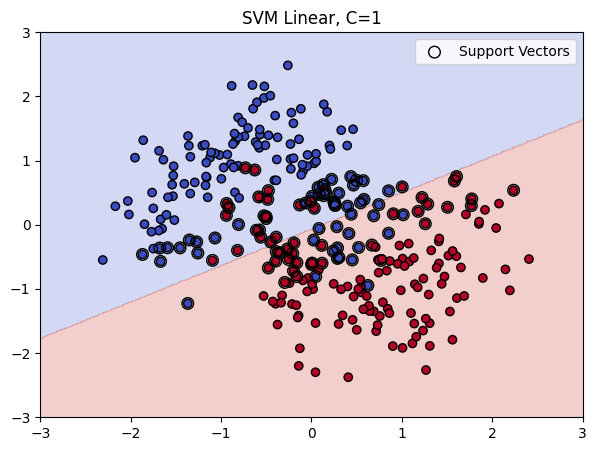

Accuracy: 0.86
Support vectors: 101


In [7]:
lin = SVC(kernel="linear", C=1)

lin.fit(X2, y2)

plot_boundary(
    lin, X2, y2,
    "SVM Linear, C=1"
)

print("Accuracy:", lin.score(X2, y2))
print("Support vectors:", len(lin.support_vectors_))

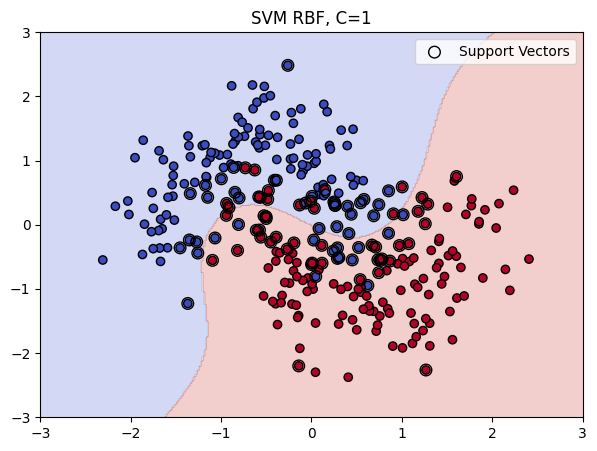

Accuracy: 0.91
Support vectors: 92


In [8]:
rbf = SVC(
    kernel="rbf",
    C=1,
    gamma="scale"
)

rbf.fit(X2, y2)

plot_boundary(
    rbf, X2, y2,
    "SVM RBF, C=1"
)

print("Accuracy:", rbf.score(X2, y2))
print("Support vectors:", len(rbf.support_vectors_))

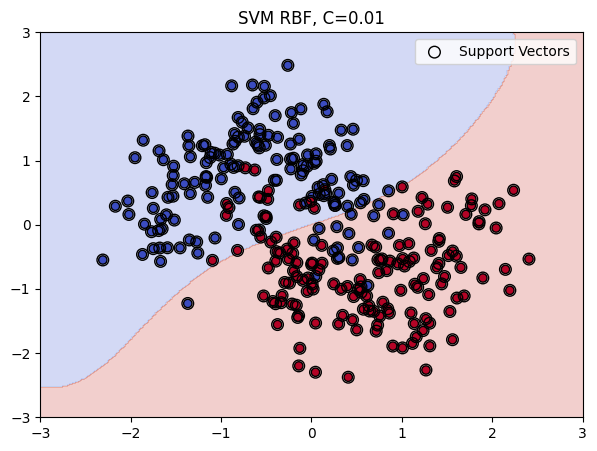

C=0.01, Accuracy=0.870, Support Vectors=300


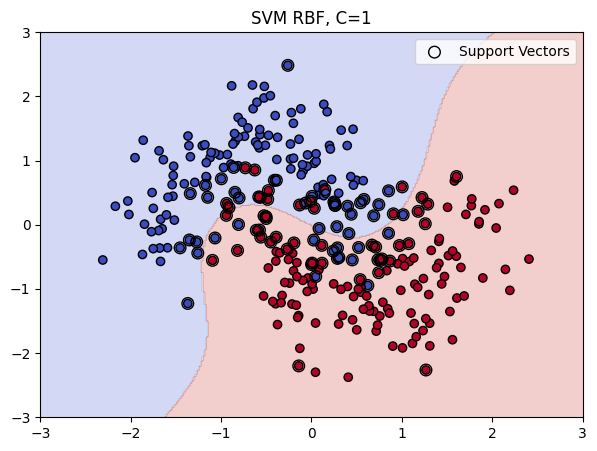

C=1, Accuracy=0.910, Support Vectors=92


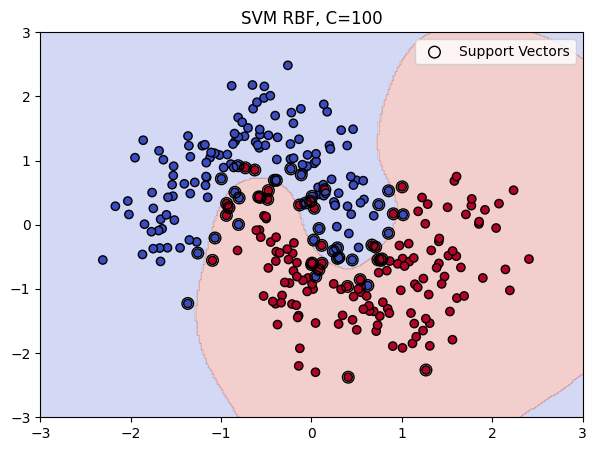

C=100, Accuracy=0.937, Support Vectors=57


In [9]:
for C in [0.01, 1, 100]:

    model = SVC(
        kernel="rbf",
        C=C,
        gamma="scale"
    )

    model.fit(X2, y2)

    plot_boundary(
        model,
        X2,
        y2,
        f"SVM RBF, C={C}"
    )

    print(
        f"C={C}, "
        f"Accuracy={model.score(X2, y2):.3f}, "
        f"Support Vectors={len(model.support_vectors_)}"
    )

In [11]:
print("Линейная модель:", round(lin.score(X2, y2), 3))
print("RBF модель:", round(rbf.score(X2, y2), 3))

Линейная модель: 0.86
RBF модель: 0.91


In [12]:

def plot_boundary(model, X, y, title, fname):

    xx, yy = np.meshgrid(
        np.linspace(-3, 3, 300),
        np.linspace(-3, 3, 300)
    )

    zz = model.predict(
        np.c_[xx.ravel(), yy.ravel()]
    ).reshape(xx.shape)

    plt.figure(figsize=(5, 4))

    plt.contourf(
        xx, yy, zz,
        alpha=0.25,
        cmap="coolwarm"
    )

    plt.scatter(
        X[:, 0], X[:, 1],
        c=y,
        cmap="coolwarm",
        s=18,
        edgecolor="k"
    )

    sv = model.support_vectors_

    plt.scatter(
        sv[:, 0], sv[:, 1],
        s=70,
        facecolors="none",
        edgecolors="k"
    )

    plt.title(
        f"{title}: train acc={model.score(X, y):.3f}, SV={len(sv)}"
    )

    plt.tight_layout()
    plt.savefig(fname, dpi=120)
    plt.close()

print("Функция plot_boundary создана!")


Функция plot_boundary создана!


In [13]:
lin = SVC(kernel="linear", C=1)
lin.fit(X2, y2)

plot_boundary(
    lin,
    X2,
    y2,
    "linear, C=1",
    "linear_C1.png"
)

print("Линейная модель готова!")

Линейная модель готова!


In [14]:
rbf = SVC(kernel="rbf", C=1, gamma="scale")
rbf.fit(X2, y2)

plot_boundary(
    rbf,
    X2,
    y2,
    "RBF, C=1",
    "rbf_C1.png"
)

print("RBF модель готова!")

RBF модель готова!


In [15]:
import os

print("Созданные файлы:")

for file in os.listdir():
    if file.endswith(".png"):
        print(file)

Созданные файлы:
svm_rbf_C1.png
svm_linear.png
svm_rbf.png
svm_rbf_C0.01.png
linear_C1.png
rbf_C1.png
svm_rbf_C100.png
grid.png


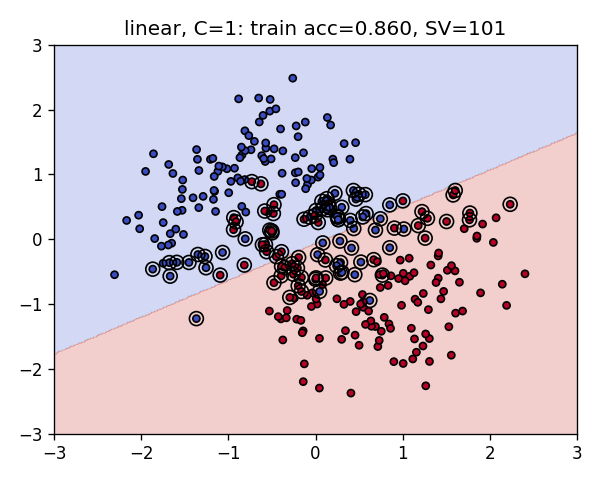

In [16]:
from IPython.display import display, Image

display(Image(filename="linear_C1.png"))

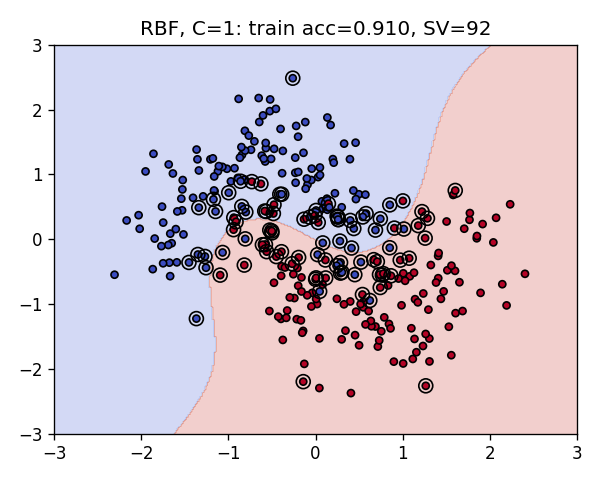

In [17]:
display(Image(filename="rbf_C1.png"))

In [19]:

lin = SVC(kernel="linear", C=1).fit(X2, y2)

plot_boundary(
    lin, X2, y2,
    "linear, C=1",
    "svm_linear.png"
)

print(
    "linear: acc=%.3f опорных=%d"
    % (lin.score(X2, y2), len(lin.support_vectors_))
)


linear: acc=0.860 опорных=101


In [20]:

lin = SVC(kernel="linear", C=1).fit(X2, y2)

plot_boundary(
    lin, X2, y2,
    "linear, C=1",
    "svm_linear.png"
)

print("linear: acc=%.3f опорных=%d" % (lin.score(X2, y2), len(lin.support_vectors_)))


linear: acc=0.860 опорных=101


In [21]:

lin = SVC(kernel="linear", C=1).fit(X2, y2)
plot_boundary(lin, X2, y2, "linear, C=1", "svm_linear.png")
print("linear: acc=%.3f опорных=%d" % (lin.score(X2, y2), len(lin.support_vectors_)))


linear: acc=0.860 опорных=101


# Практическая работа №9 — Support Vector Machine (SVM)

**Дисциплина:** Machine Learning  
**Тема:** Метод опорных векторов (SVM)  
**Уровень:** A

## Цель работы

Изучить метод опорных векторов (Support Vector Machine), научиться строить границы классификации и определять опорные векторы.

## Используемые инструменты

- Google Colab
- Python
- NumPy
- Matplotlib
- Scikit-learn

## Выполненные задания

1. Проверка рабочего окружения и библиотек.
2. Создание искусственного набора данных `make_moons`.
3. Масштабирование данных с помощью `StandardScaler`.
4. Создание функции `plot_boundary` для визуализации границ решений.
5. Обучение модели SVM с линейным ядром (`Linear`).
6. Визуализация классов и опорных векторов.
7. Сохранение графика в формате PNG.

## Результаты

Для линейной модели SVM использовались следующие параметры:

- Kernel: Linear
- C: 1
- Количество объектов: 300
- Accuracy: 0.860
- Количество опорных векторов: 101

## Вывод

В ходе практической работы был изучен метод опорных векторов (SVM). Была создана линейная модель классификации для искусственного набора данных `make_moons`.

Результат показал, что линейная граница не может идеально разделить два нелинейных класса. Точность модели составила 86%. Также были определены и визуализированы 101 опорный вектор.

Практическая работа помогла понять принцип работы SVM и особенности линейной классификации.